<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_2_Regression/Projects/Instructions/Project.2-Housing/Housing-Pass-03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2 - Pass 03: Housing Price Prediction


The project should be done using Regression prediction techniques ( with feature scaling and regularization ) as covered in class.
The goal is to minimize the RMS ***percentage*** error ( root mean squared percentage error - RMSPE ) on your prediction of the house sales price.



Any of the available features can be used in the regression, but a minimum set of variables that do the job should be the ultimate goal.



Be sure to go through the whole data science process and document as such in your Jupyter notebook.



This project will have less direct "To Do" guidance and the progression through the data science process will be more individualized this time around.  We will talk about all the issues during class so you're not going to be out on a ledge with this one, I just want to move you towards performing a data science project on your own eventually.

There are two parts to this data set, both of which are on AWS:

- [Housing Data Dictionary]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Housing%20-%20Data%20Documentation.pdf )
- [Data Set]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv)


In [ ]:
! curl -s -I https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv

HTTP/1.1 200 OK
x-amz-id-2: MKQGhgeZ0fMxizg8WZYYl4LQWXp9zx2lsA/sGRwQiBLYLeESmimmx5EhzamLDW8jzlQYRN2owTguUZyv4PhoaVez1hNINNc3
x-amz-request-id: NT891JJTXHRP02KK
Server: AmazonS3
Date: Sat, 24 Oct 2026 15:08:00 GMT
Last-Modified: Fri, 06 Oct 2023 04:00:27 GMT
ETag: "76e84c9ee7f6fd4d51276697f81e76e1"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 880420
Content-Type: text/csv



In [ ]:
! curl -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv | head -2

PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
905101070,20,RL,62.0,14299,Pave,,Reg,Lvl,AllPub,Inside,G

## Problem Definition

### Business Problem

Target is *Sales Price* and feature is *Lot Frontage*

Help investors evaluate whether lot frontage might be a useful factor when assessing a property's potential market value.

### Data Science Problem

Supervised regression

## Data Collection/Sources

### Load Modules

In [ ]:
# Import the libraries and modules
from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

### Load Data

In [ ]:
# Define the data's url as 'url'
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [ ]:
# Define the data frame as 'df'
df = pd.read_csv(url)

## Data Cleaning

### Overview

In [ ]:
# Display the head - 81 columns
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [ ]:
# Display the tail - target is the last row
df.tail()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,528292060,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


In [ ]:
# See the shape - 2637 rows, 81 columns
df.shape

(2637, 81)

In [ ]:
# See how many total entries
df.size

213597

### Summary Statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

In [ ]:
# Summary meta-data - our target 'SalePrice' is int64, our feature 'Lot Frontage' is float64
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   MS Zoning        2637 non-null   object 
 3   Lot Frontage     2188 non-null   float64
 4   Lot Area         2637 non-null   int64  
 5   Street           2637 non-null   object 
 6   Alley            180 non-null    object 
 7   Lot Shape        2637 non-null   object 
 8   Land Contour     2637 non-null   object 
 9   Utilities        2637 non-null   object 
 10  Lot Config       2637 non-null   object 
 11  Land Slope       2637 non-null   object 
 12  Neighborhood     2637 non-null   object 
 13  Condition 1      2637 non-null   object 
 14  Condition 2      2637 non-null   object 
 15  Bldg Type        2637 non-null   object 
 16  House Style      2637 non-null   object 
 17  Overall Qual  

In [ ]:
# See the summary statistics
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
PID,2637.0,7.141301e+08,1.887527e+08,526301100.0,5.284770e+08,535453040.0,9.071870e+08,1.007100e+09
MS SubClass,2637.0,5.734926e+01,4.249909e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2188.0,6.916682e+01,2.335678e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2637.0,1.004469e+04,6.742550e+03,1300.0,7.436000e+03,9450.0,1.152600e+04,1.646600e+05
Overall Qual,2637.0,6.097459e+00,1.411522e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2637.0,5.569966e+00,1.118262e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2637.0,1.971289e+03,3.030699e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2637.0,1.984203e+03,2.091308e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2614.0,1.018879e+02,1.795782e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03
BsmtFin SF 1,2636.0,4.384412e+02,4.496023e+02,0.0,0.000000e+00,368.0,7.320000e+02,5.644000e+03


### Target Nulls


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [ ]:
# Define the name of the target column 'SalePrice' to work with it independently
target_col = 'SalePrice'
df[target_col]

,SalePrice
0,115400
1,90000
2,141000
3,254000
4,155000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [ ]:
# Look for nulls in the target 'SalePrice' (dropping rows if 20% nulls or under) - no nulls in the target
df[target_col].isnull().sum() / df[target_col].shape[0] * 100


np.float64(0.0)

### Feature Nulls

In [ ]:
# Define the name of the feature columns to work with them independently (all floats are features)
feature_cols = df.select_dtypes(include=['float']).columns
df[feature_cols]

,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


In [ ]:
# Look for nulls in the features (dropping rows if 20% nulls or under) - 17% is the highest proportion of nulls in 'Lot Frontage'
(df[feature_cols].isnull().sum() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
Lot Frontage,17.026925
Garage Yr Blt,5.574516
Mas Vnr Area,0.872203
Bsmt Half Bath,0.075844
Bsmt Full Bath,0.075844
BsmtFin SF 1,0.037922
BsmtFin SF 2,0.037922
Total Bsmt SF,0.037922
Bsmt Unf SF,0.037922
Garage Cars,0.037922


### Identifier Columns

In [ ]:
# See proportion of unique values in the target column
(df[target_col].nunique() / df[target_col].shape[0] * 100) #.sort_values(ascending=False)

37.2772089495639

In [ ]:
# See proportion of unique values in the feature columns
(df[feature_cols].nunique() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
Bsmt Unf SF,40.955631
Total Bsmt SF,37.959803
BsmtFin SF 1,35.456959
Garage Area,21.843003
Mas Vnr Area,16.116799
BsmtFin SF 2,9.594236
Lot Frontage,4.778157
Garage Yr Blt,3.868032
Garage Cars,0.227531
Bsmt Full Bath,0.151688


In [ ]:
# See for all data - PID is an identifier column
(df.nunique() / df.shape[0] * 100).sort_values(ascending=False)

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
Bsmt Unf SF,40.955631
1st Flr SF,38.756162
...,...
Bsmt Half Bath,0.113766
Paved Drive,0.113766
Street,0.075844
Alley,0.075844


In [ ]:
# See the data types of the features - continuous are good for linear regression
df[feature_cols].dtypes

,0
Lot Frontage,float64
Mas Vnr Area,float64
BsmtFin SF 1,float64
BsmtFin SF 2,float64
Bsmt Unf SF,float64
Total Bsmt SF,float64
Bsmt Full Bath,float64
Bsmt Half Bath,float64
Garage Yr Blt,float64
Garage Cars,float64


In [ ]:
# See the data types of the target - continuous are good for linear regression
df[target_col].dtypes

dtype('int64')

### Backup #1

In [ ]:
# Make a backup
df_bak1 = df.copy()

In [ ]:
# Restore from backup
df = df_bak1.copy()

### Cull the Nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

Feature column containing 17% nulls, so drop those rows in our dataset.

In [ ]:
# Drop null rows referencing the feature columns
df = df.dropna(subset=feature_cols)

In [ ]:
# Verify rows dropped
df.shape

(2033, 81)

### Backup #2

In [ ]:
# Make a backup
df_bak2 = df.copy()

In [ ]:
# Restore from backup
df = df_bak2.copy()

### Working Data Frame

In [ ]:
# Define our target and feature columns as a data frame to work with 'iso_df'
iso_df = pd.concat([df[[target_col]], df[feature_cols]], axis=1).reset_index(drop=True)

In [ ]:
# Verify the working data frame
iso_df

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2028,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2029,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2030,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2031,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


## EDA (Exploratory Data Analysis)

### Linear Regression Check

Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

#### Correlation with Target

In [ ]:
# Calculate a correlation matrix for the target
corr_mat = iso_df.corr()
corr_mat

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
SalePrice,1.000000,0.353584,0.523401,0.434640,-0.015075,0.191868,0.646068,0.288551,-0.060586,0.547303,0.657323,0.637670
Lot Frontage,0.353584,1.000000,0.222444,0.219236,0.031789,0.113155,0.357713,0.118205,-0.043326,0.091115,0.316999,0.376226
Mas Vnr Area,0.523401,0.222444,1.000000,0.310326,-0.043921,0.092423,0.403243,0.161279,-0.033380,0.271761,0.363479,0.374083
BsmtFin SF 1,0.434640,0.219236,0.310326,1.000000,-0.058864,-0.487853,0.533863,0.643038,0.069358,0.191797,0.217463,0.278637
BsmtFin SF 2,-0.015075,0.031789,-0.043921,-0.058864,1.000000,-0.250209,0.070244,0.182792,0.103193,-0.058353,-0.054672,-0.030608
Bsmt Unf SF,0.191868,0.113155,0.092423,-0.487853,-0.250209,1.000000,0.405292,-0.412600,-0.119023,0.189185,0.248846,0.222307
Total Bsmt SF,0.646068,0.357713,0.403243,0.533863,0.070244,0.405292,1.000000,0.328114,-0.008016,0.371220,0.460192,0.506887
Bsmt Full Bath,0.288551,0.118205,0.161279,0.643038,0.182792,-0.412600,0.328114,1.000000,-0.130969,0.151842,0.154109,0.187594
Bsmt Half Bath,-0.060586,-0.043326,-0.033380,0.069358,0.103193,-0.119023,-0.008016,-0.130969,1.000000,-0.043840,-0.053841,-0.050673
Garage Yr Blt,0.547303,0.091115,0.271761,0.191797,-0.058353,0.189185,0.371220,0.151842,-0.043840,1.000000,0.598678,0.586653


##### Correlation Matrix

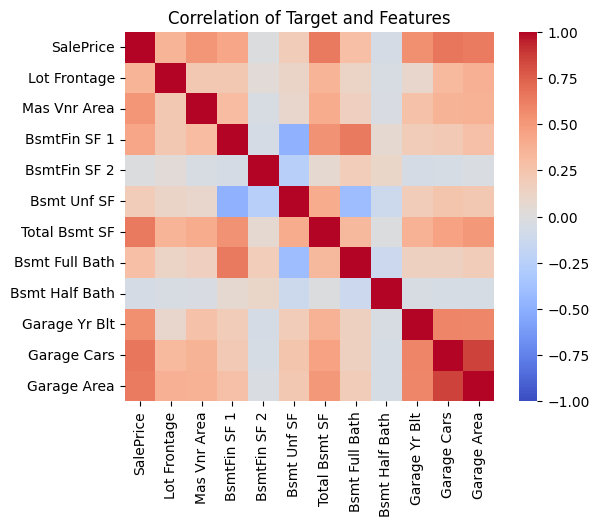

In [ ]:
# Display the correlation matrix - check if features correlated with the target
sns.heatmap(
    corr_mat,
    square=True,
    annot=False,
    fmt='d',
    cbar=True,
    cmap='coolwarm',
    vmin=-1,vmax=1
)

plt.title('Correlation of Target and Features');

Couple features have low correlation with the target. Most have a high correlation of 0.5 or higher. Some of these features do have a high correlation with each other. They are not the best features to go with this target for our linear regression model.

##### Correlation Ranking

In [ ]:
corr_mat = iso_df.corr().round(2).unstack().abs()
corr_mat.reset_index()

,level_0,level_1,0
0,SalePrice,SalePrice,1.00
1,SalePrice,Lot Frontage,0.35
2,SalePrice,Mas Vnr Area,0.52
3,SalePrice,BsmtFin SF 1,0.43
4,SalePrice,BsmtFin SF 2,0.02
...,...,...,...
139,Garage Area,Bsmt Full Bath,0.19
140,Garage Area,Bsmt Half Bath,0.05
141,Garage Area,Garage Yr Blt,0.59
142,Garage Area,Garage Cars,0.85


In [ ]:
# Create a data series with features ranked by correlation
corr_mat = corr_mat[corr_mat < 1]
corr_mat.reset_index()

,level_0,level_1,0
0,SalePrice,Lot Frontage,0.35
1,SalePrice,Mas Vnr Area,0.52
2,SalePrice,BsmtFin SF 1,0.43
3,SalePrice,BsmtFin SF 2,0.02
4,SalePrice,Bsmt Unf SF,0.19
...,...,...,...
127,Garage Area,Total Bsmt SF,0.51
128,Garage Area,Bsmt Full Bath,0.19
129,Garage Area,Bsmt Half Bath,0.05
130,Garage Area,Garage Yr Blt,0.59


In [ ]:
corr_mat.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,Garage Cars,Garage Area,0.85
1,Garage Cars,SalePrice,0.66
2,Total Bsmt SF,SalePrice,0.65
3,BsmtFin SF 1,Bsmt Full Bath,0.64
4,Bsmt Full Bath,BsmtFin SF 1,0.64
...,...,...,...
61,Bsmt Half Bath,Mas Vnr Area,0.03
62,Garage Area,BsmtFin SF 2,0.03
63,BsmtFin SF 2,Lot Frontage,0.03
64,SalePrice,BsmtFin SF 2,0.02


#### Independence of Features
Doesn't make sense for a single feature.

##### Correlation Matrix

In [ ]:
# Make a correlation matrix of only features
corr_feat = iso_df.drop(columns=target_col).corr()

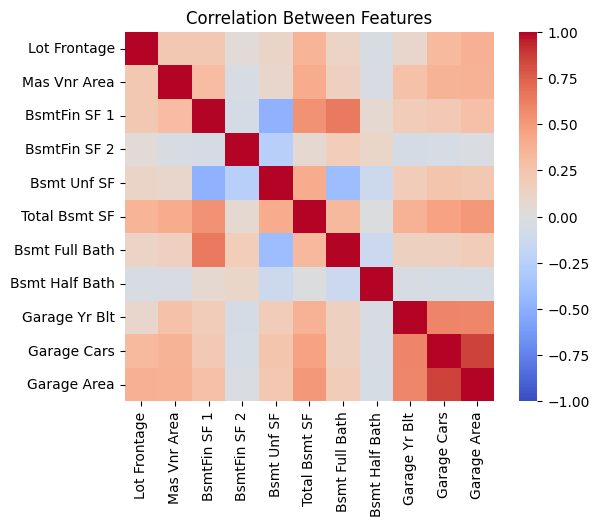

In [ ]:
# Display the correlation matrix of only features
sns.heatmap(
    corr_feat,
    square=True,
    annot=False,
    fmt='d',
    cbar=True,
    cmap='coolwarm',
    vmin=-1,vmax=1
)

plt.title('Correlation Between Features');

##### Correlation Ranking

In [ ]:
# Calculate a correlation matrix for the features
corr_feat2 = iso_df.drop(columns=target_col).corr().round(2).unstack().abs()
corr_feat2.reset_index()

,level_0,level_1,0
0,Lot Frontage,Lot Frontage,1.00
1,Lot Frontage,Mas Vnr Area,0.22
2,Lot Frontage,BsmtFin SF 1,0.22
3,Lot Frontage,BsmtFin SF 2,0.03
4,Lot Frontage,Bsmt Unf SF,0.11
...,...,...,...
116,Garage Area,Bsmt Full Bath,0.19
117,Garage Area,Bsmt Half Bath,0.05
118,Garage Area,Garage Yr Blt,0.59
119,Garage Area,Garage Cars,0.85


In [ ]:
# Create a data series with features ranked by correlation
corr_feat2 = corr_feat2[corr_feat2 < 1]
corr_feat2.reset_index()

,level_0,level_1,0
0,Lot Frontage,Mas Vnr Area,0.22
1,Lot Frontage,BsmtFin SF 1,0.22
2,Lot Frontage,BsmtFin SF 2,0.03
3,Lot Frontage,Bsmt Unf SF,0.11
4,Lot Frontage,Total Bsmt SF,0.36
...,...,...,...
105,Garage Area,Total Bsmt SF,0.51
106,Garage Area,Bsmt Full Bath,0.19
107,Garage Area,Bsmt Half Bath,0.05
108,Garage Area,Garage Yr Blt,0.59


In [ ]:
corr_feat2.sort_values(ascending = False)[::2].reset_index()


,level_0,level_1,0
0,Garage Area,Garage Cars,0.85
1,BsmtFin SF 1,Bsmt Full Bath,0.64
2,Garage Yr Blt,Garage Cars,0.60
3,Garage Area,Garage Yr Blt,0.59
4,Total Bsmt SF,BsmtFin SF 1,0.53
5,Garage Area,Total Bsmt SF,0.51
6,Bsmt Unf SF,BsmtFin SF 1,0.49
7,Total Bsmt SF,Garage Cars,0.46
8,Total Bsmt SF,Bsmt Unf SF,0.41
9,Bsmt Unf SF,Bsmt Full Bath,0.41


What do we notice?

*   Many predictors are highly correlated to each other
*   Many predictors are highly correlated with Garage Area



## Data Processing

## Data Visualization

## Communication of Results